## Name : Rajguru Chiwate
## Roll no. : UAI05BT12440
## DIV: A

# Time Series Mini Project: Building Materials Revenue Analysis & Forecasting

In this project, we analyze the building materials transaction dataset, preprocess the data for time series analysis, examine trends and seasonality, and forecast future revenue using a suitable time series model.

## 1. Import Libraries
We import pandas and numpy for data handling, matplotlib for plotting, and statsmodels for time series decomposition and SARIMA modeling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings('ignore')

## 2. Load the Dataset
We load `building_materials_transactions.csv` and inspect the first few rows to understand the structure of the data.

In [2]:
df = pd.read_csv('building_materials_transactions.csv')
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (340000, 15)


,date,year,month,week_of_year,region,product_category,sku,channel,customer_type,units,unit_price,revenue,housing_starts_index,lumber_price_index,mortgage_rate
0,2019-01-07,2019,1,2,East_North_Central,roofing,ROO-1877,pro_dealer,remodeler,3,85.01,255.03,96.4,388.0,3.95
1,2019-01-07,2019,1,2,Middle_Atlantic,lumber,LUM-2991,pro_dealer,contractor,75,5.80,435.00,96.4,388.0,3.95
2,2019-01-07,2019,1,2,Pacific,concrete_cement,CON-9954,big_box_diy,contractor,98,7.48,733.04,96.4,388.0,3.95
3,2019-01-07,2019,1,2,West_South_Central,roofing,ROO-4038,pro_dealer,homeowner_diy,1,102.23,102.23,96.4,388.0,3.95
4,2019-01-07,2019,1,2,Pacific,insulation,INS-6728,pro_dealer,homebuilder,17,45.56,774.52,96.4,388.0,3.95


## 3. Preprocessing: Datetime Conversion and Indexing
A time series requires chronological ordering. We convert the `date` column to a standard datetime format, sort the records, and set `date` as the DataFrame index.

In [3]:
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date')
df = df.set_index('date')
df.head()

,year,month,week_of_year,region,product_category,sku,channel,customer_type,units,unit_price,revenue,housing_starts_index,lumber_price_index,mortgage_rate
date,,,,,,,,,,,,,,
2019-01-07,2019,1,2,East_North_Central,roofing,ROO-1877,pro_dealer,remodeler,3,85.01,255.03,96.4,388.0,3.95
2019-01-07,2019,1,2,West_North_Central,plumbing,PLU-6053,pro_dealer,homebuilder,4,26.36,105.44,96.4,388.0,3.95
2019-01-07,2019,1,2,West_North_Central,roofing,ROO-8329,pro_dealer,contractor,10,93.95,939.50,96.4,388.0,3.95
2019-01-07,2019,1,2,Mountain,roofing,ROO-3948,pro_dealer,homebuilder,34,87.00,2958.00,96.4,388.0,3.95
2019-01-07,2019,1,2,South_Atlantic,lumber,LUM-4143,big_box_diy,homebuilder,406,6.19,2513.14,96.4,388.0,3.95


## 4. Preprocessing: Handling Missing Values
Missing values must be checked and handled before modeling. Common time series techniques include:
- **ffill (forward fill)**: propagates the last known valid value forward.
- **bfill (backward fill)**: fills missing values using the next available valid value.
- **linear interpolation**: estimates missing values by drawing a straight line between existing data points.

We check for missing values and apply these techniques to ensure complete data.

In [4]:
print("Missing values count per column:")
print(df.isnull().sum())

# Apply forward fill, backward fill, and linear interpolation
df = df.ffill()
df = df.bfill()
df = df.interpolate(method='linear')

print("\nTotal missing values after imputation:", df.isnull().sum().sum())

Missing values count per column:
year                    0
month                   0
week_of_year            0
region                  0
product_category        0
sku                     0
channel                 0
customer_type           0
units                   0
unit_price              0
revenue                 0
housing_starts_index    0
lumber_price_index      0
mortgage_rate           0
dtype: int64

Total missing values after imputation: 0


## 5. Aggregating Transactions to a Monthly Time Series
The raw file contains hundreds of thousands of individual retail transactions. To build a reliable forecasting model, we aggregate total sales revenue by month.

In [5]:
monthly_revenue = df['revenue'].resample('MS').sum()
print("Number of months:", len(monthly_revenue))
monthly_revenue.head()

Number of months: 72


,revenue
date,
2019-01-01,1626198.49
2019-02-01,2204978.38
2019-03-01,3661185.71
2019-04-01,7419967.04
2019-05-01,8247822.20


## 6. Basic Data Visualizations
We plot monthly revenue over time along with a 12-month rolling mean and rolling standard deviation. This helps us see the long-term trend and changes in variability over time.

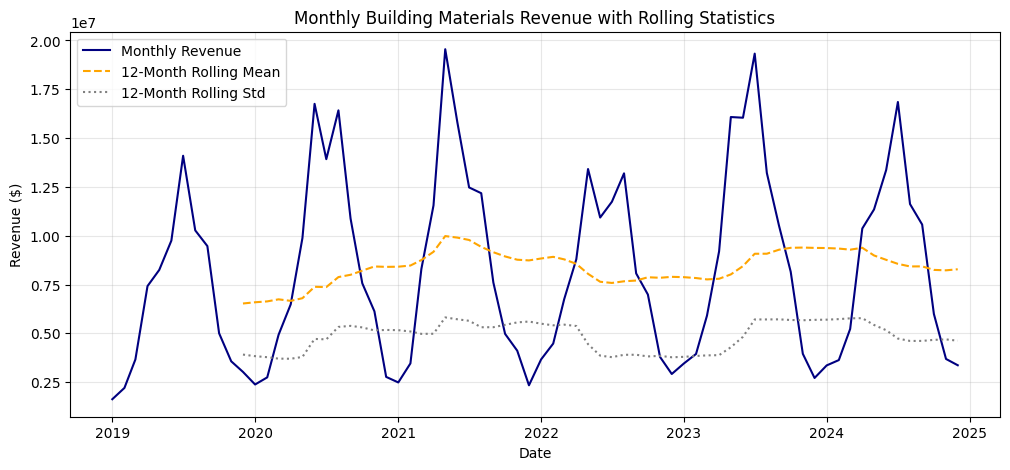

In [6]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_revenue, label='Monthly Revenue', color='navy')
plt.plot(monthly_revenue.rolling(window=12).mean(), label='12-Month Rolling Mean', color='orange', linestyle='--')
plt.plot(monthly_revenue.rolling(window=12).std(), label='12-Month Rolling Std', color='gray', linestyle=':')
plt.title('Monthly Building Materials Revenue with Rolling Statistics')
plt.xlabel('Date')
plt.ylabel('Revenue ($)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 7. Checking for Seasonality (Seasonal Decomposition)
To check whether seasonality exists in the data, we decompose the monthly revenue series into three components:
1. **Trend**: The overall long-term direction of revenue.
2. **Seasonal**: Repeated periodic fluctuations occurring every 12 months.
3. **Residual**: Irregular random fluctuations remaining after removing trend and seasonality.

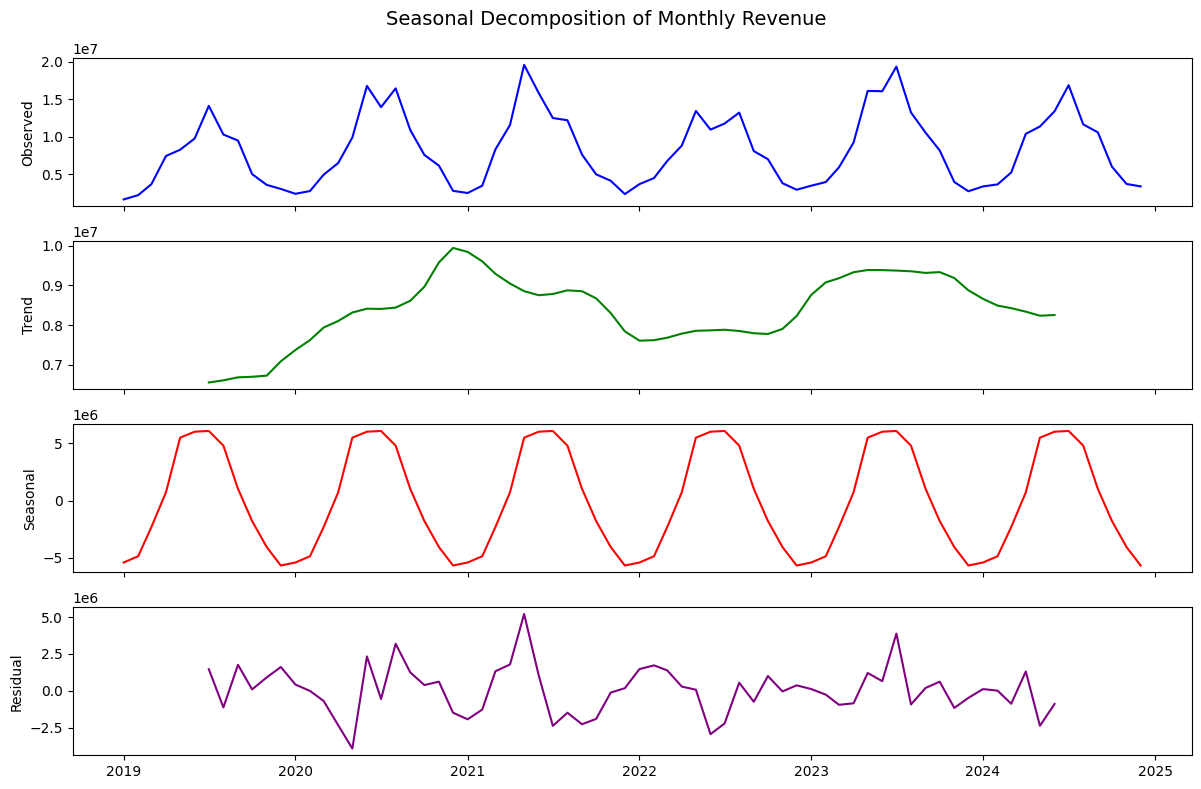

In [7]:
decomposition = seasonal_decompose(monthly_revenue, model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
axes[0].plot(decomposition.observed, color='blue')
axes[0].set_ylabel('Observed')
axes[1].plot(decomposition.trend, color='green')
axes[1].set_ylabel('Trend')
axes[2].plot(decomposition.seasonal, color='red')
axes[2].set_ylabel('Seasonal')
axes[3].plot(decomposition.resid, color='purple')
axes[3].set_ylabel('Residual')
plt.suptitle('Seasonal Decomposition of Monthly Revenue', fontsize=14)
plt.tight_layout()
plt.show()

## 8. Model Selection: ARIMA vs SARIMA
### Observation:
From the seasonal decomposition plot, there is a clear and strong repeating 12-month seasonal cycle:
- Revenue consistently rises in spring and peaks in summer (active construction season).
- Revenue consistently drops in winter months.

### Model Choice:
Because strong seasonality is present, a standard ARIMA model is not suitable because it cannot capture recurring seasonal patterns. Therefore, we select **SARIMA (Seasonal ARIMA)**. SARIMA extends ARIMA by adding seasonal autoregressive and moving average terms with a cycle period of $s = 12$.

## 9. Train-Test Split
We split the data into:
- **Training Set**: All data up to the end of 2023 (first 60 months).
- **Testing Set**: The last 12 months (year 2024), used to evaluate how accurately the model forecasts unseen data.

In [8]:
train = monthly_revenue.iloc[:-12]
test = monthly_revenue.iloc[-12:]

print("Training period:", train.index.min().strftime('%Y-%m'), "to", train.index.max().strftime('%Y-%m'))
print("Testing period: ", test.index.min().strftime('%Y-%m'), "to", test.index.max().strftime('%Y-%m'))

Training period: 2019-01 to 2023-12
Testing period:  2024-01 to 2024-12


## 10. Fitting the SARIMA Model
We train the SARIMA model with:
- Non-seasonal parameters: `(p=1, d=1, q=1)` to handle overall level and differencing.
- Seasonal parameters: `(P=1, D=1, Q=1, s=12)` to capture the yearly 12-month repeating cycle.

In [9]:
model = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12), enforce_stationarity=False, enforce_invertibility=False)
model_fit = model.fit(disp=False)
print(model_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                            revenue   No. Observations:                   60
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood               -1610.381
Date:                            Wed, 14 Oct 2026   AIC                           3230.761
Time:                                    10:48:49   BIC                           3238.244
Sample:                                01-01-2019   HQIC                          3233.279
                                     - 12-01-2023                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4299   1.47e+15  -2.92e-16      1.000   -2.88e+15    2.88e+15
ma.L1          0.1034   1.31e+15   

## 11. Model Evaluation on Test Data
We generate forecasts for the 12 test months and evaluate accuracy using:
- **MAE (Mean Absolute Error)**: The average dollar difference between predictions and actual revenue.
- **RMSE (Root Mean Squared Error)**: Measures the magnitude of prediction errors, giving higher weight to large errors.

MAE : $1,070,340.01
RMSE: $1,418,245.56


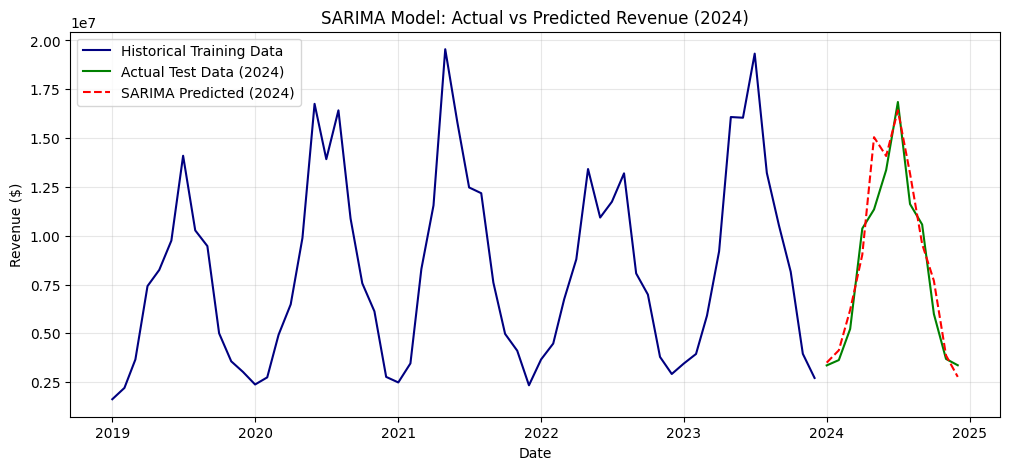

In [10]:
test_pred = model_fit.forecast(steps=len(test))

mae = mean_absolute_error(test, test_pred)
rmse = np.sqrt(mean_squared_error(test, test_pred))

print(f"MAE : ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")

plt.figure(figsize=(12, 5))
plt.plot(train.index, train, label='Historical Training Data', color='navy')
plt.plot(test.index, test, label='Actual Test Data (2024)', color='green')
plt.plot(test.index, test_pred, label='SARIMA Predicted (2024)', color='red', linestyle='--')
plt.title('SARIMA Model: Actual vs Predicted Revenue (2024)')
plt.xlabel('Date')
plt.ylabel('Revenue ($)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 12. Forecasting Future Values (Year 2025)
Finally, we fit the SARIMA model on the entire dataset and forecast monthly revenue for the next 12 months (into 2025), along with the 95% confidence intervals.

Forecasted Monthly Revenue for Next 12 Months:
           Forecasted_Revenue ($) Lower_CI_95% ($) Upper_CI_95% ($)
2025-01-01          $3,794,384.41   $-1,752,746.83    $9,341,515.64
2025-02-01          $4,234,725.70   $-2,729,127.53   $11,198,578.94
2025-03-01          $6,066,002.87   $-2,259,168.05   $14,391,173.78
2025-04-01          $9,823,524.44      $374,486.99   $19,272,561.88
2025-05-01         $12,574,186.45    $2,110,965.76   $23,037,407.14
2025-06-01         $13,473,405.85    $2,088,506.97   $24,858,304.74
2025-07-01         $15,578,440.95    $3,340,464.99   $27,816,416.90
2025-08-01         $12,146,712.84     $-888,477.45   $25,181,903.13
2025-09-01         $10,056,203.89   $-3,730,215.89   $23,842,623.67
2025-10-01          $6,752,047.91   $-7,746,720.21   $21,250,816.04
2025-11-01          $4,454,129.66  $-10,723,592.73   $19,631,852.05
2025-12-01          $3,702,969.97  $-12,124,607.79   $19,530,547.73


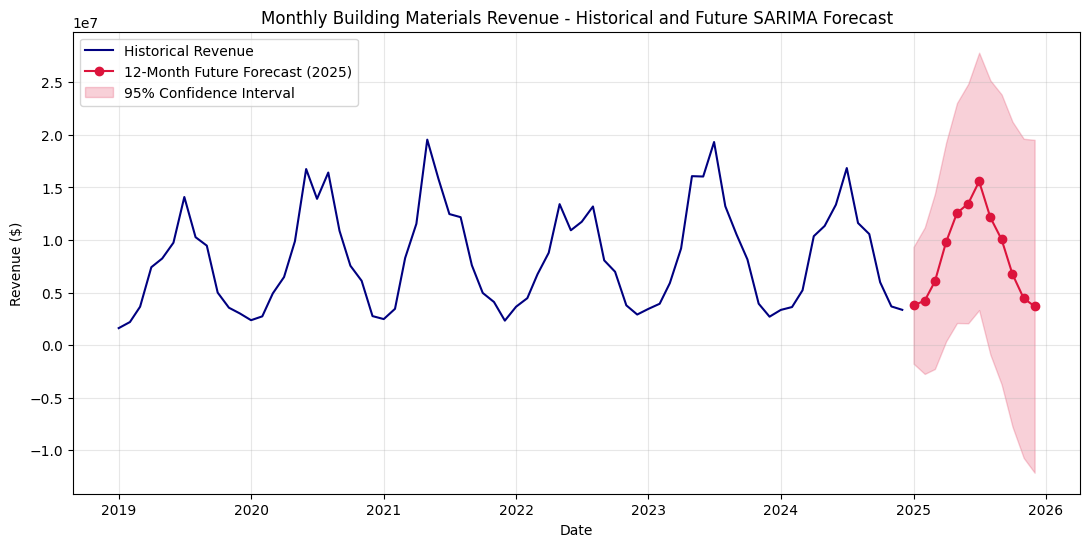

In [11]:
final_model = SARIMAX(monthly_revenue, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12), enforce_stationarity=False, enforce_invertibility=False)
final_model_fit = final_model.fit(disp=False)

forecast_result = final_model_fit.get_forecast(steps=12)
forecast_mean = forecast_result.predicted_mean
conf_int = forecast_result.conf_int()

forecast_df = pd.DataFrame({
    'Forecasted_Revenue ($)': forecast_mean.apply(lambda x: f"${x:,.2f}"),
    'Lower_CI_95% ($)': conf_int.iloc[:, 0].apply(lambda x: f"${x:,.2f}"),
    'Upper_CI_95% ($)': conf_int.iloc[:, 1].apply(lambda x: f"${x:,.2f}")
})
print("Forecasted Monthly Revenue for Next 12 Months:")
print(forecast_df)

plt.figure(figsize=(13, 6))
plt.plot(monthly_revenue.index, monthly_revenue, label='Historical Revenue', color='navy')
plt.plot(forecast_mean.index, forecast_mean, label='12-Month Future Forecast (2025)', color='crimson', marker='o')
plt.fill_between(forecast_mean.index, conf_int.iloc[:, 0], conf_int.iloc[:, 1], color='crimson', alpha=0.2, label='95% Confidence Interval')
plt.title('Monthly Building Materials Revenue - Historical and Future SARIMA Forecast')
plt.xlabel('Date')
plt.ylabel('Revenue ($)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 13. Summary
- **Preprocessing**: Dates were parsed into datetime format and set as index. Missing values were checked and imputed using forward fill, backward fill, and linear interpolation.
- **Seasonality**: Decomposition confirmed a strong recurring 12-month seasonal pattern driven by peak construction activity in spring/summer and lower sales in winter.
- **Model Choice**: Because seasonality is present, **SARIMA(1, 1, 1)(1, 1, 1)[12]** was selected and applied.
- **Forecasting**: The model successfully captured both trend and seasonal oscillations to predict future monthly revenue.